# 02 · EDA de los retornos (Bloque 2) — solo train

Caracteriza las series **ya transformadas** (log-retornos y diferencias) con datos de **2010-2018**.
Lee `data/processed/`; el test no se abre. 

In [16]:
import sys
from pathlib import Path

# La raíz del proyecto es la carpeta que contiene `src/` (funciona se ejecute desde la raíz o desde notebooks/)
RAIZ = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import importlib

from src import config as cfg

from src.preprocessing import cargar
from src import eda_utils as eda

In [17]:
importlib.reload(cfg)
importlib.reload(eda)

<module 'src.eda_utils' from 'c:\\Users\\ASUS\\Desktop\\Maestria IA USFQ\\TESIS\\DESARROLLO TESIS\\src\\eda_utils.py'>

In [18]:
ret_train = cargar("retornos", "train")
print(ret_train.shape, ret_train.index.min().date(), "->", ret_train.index.max().date())
print("nulos:", ret_train.isna().sum().sum())
ret_train.head()

(2259, 7) 2010-01-05 -> 2018-12-31
nulos: 0


,WTI,VIX,DXY,GOLD,SP500,NG,TNX
Date,,,,,,,
2010-01-05,0.003185,-0.035038,0.001160,0.000358,0.003111,-0.042885,-0.086
2010-01-06,0.017097,-0.009868,-0.001676,0.015795,0.000545,0.063906,0.053
2010-01-07,-0.006271,-0.005233,0.005405,-0.002468,0.003993,-0.034366,0.014
2010-01-08,0.001088,-0.050024,-0.005664,0.004491,0.002878,-0.009866,-0.014
2010-01-11,-0.002783,-0.032514,-0.006085,0.010922,0.001745,-0.052677,0.010


In [4]:
tabla_train = eda.tabla_estadisticos(ret_train)
with pd.option_context("display.float_format", "{:.4g}".format, "display.max_columns", None):
    display(tabla_train.T)

,n,media,std,min,p01,p05,mediana,p95,p99,max,asimetria,curtosis_exceso,JB_stat,JB_p,t_gl,ADF_stat,ADF_p,KPSS_stat,KPSS_p,LB_r_p(10),LB_r2_p(10),ARCH_LM_p(10),autocorr_r_lag1,autocorr_r2_lag1,apalancamiento,VaR_1%,VaR_5%,ES_1%,ES_5%
WTI,2259,-0.000259,0.02061,-0.1079,-0.05672,-0.03406,0.0003636,0.03028,0.054,0.1162,0.003834,2.97,830.4,4.764e-181,4.068,-33.53,0,0.09843,0.1,0.02338,8.438e-137,5.245e-55,-0.07098,0.2517,-0.0103,0.05672,0.03406,0.0701,0.04858
VIX,2259,0.0001053,0.07779,-0.3506,-0.1787,-0.1086,-0.005189,0.1255,0.2556,0.7682,1.113,7.218,5370,0,3.495,-15.43,2.945e-28,0.04018,0.1,5.423e-05,5.26e-29,1.121e-19,-0.06122,0.1778,0.1195,0.1787,0.1086,0.225,0.1534
DXY,2259,9.538e-05,0.004622,-0.02399,-0.01123,-0.007433,0.0001057,0.007705,0.01244,0.02032,0.06682,1.282,156.5,1.061e-34,6.345,-47.12,0,0.06334,0.1,0.9117,5.106e-14,1.192e-08,0.007824,0.06495,-0.000435,0.01123,0.007433,0.01381,0.009945
GOLD,2259,5.943e-05,0.01024,-0.09821,-0.02899,-0.01634,0.0001535,0.01573,0.02518,0.04603,-0.7584,6.927,4733,0,3.556,-49.38,0,0.1539,0.1,0.4407,2.486e-13,1.617e-08,-0.03892,0.1116,-0.0705,0.02899,0.01634,0.04129,0.02494
SP500,2259,0.0003516,0.009473,-0.06896,-0.0287,-0.01591,0.0005379,0.01434,0.0242,0.0484,-0.4811,4.584,2065,0,2.663,-10.45,1.429e-18,0.06469,0.1,0.0007839,6.322e-222,6.178e-88,-0.04373,0.2455,-0.1418,0.0287,0.01591,0.03714,0.02377
NG,2259,-0.0003071,0.02799,-0.1805,-0.06959,-0.0428,-0.0005126,0.04413,0.07752,0.1669,0.1545,3.195,969.8,2.519e-211,5.174,-50.14,0,0.06878,0.1,0.05053,6.692e-72,1.38e-38,-0.05713,0.2327,0.02889,0.06959,0.0428,0.09321,0.06106
TNX,2259,-0.0005113,0.0489,-0.219,-0.1254,-0.0771,-0.002,0.079,0.1253,0.224,0.1247,1.307,166.7,6.263e-37,7.124,-49.11,0,0.2176,0.1,0.2796,1.773e-57,1.732e-26,-0.033,0.1236,0.02558,0.1254,0.0771,0.15,0.1061


### Series transformadas (train)

Vista general de las siete series ya transformadas. La banda roja es la desviación móvil de 63 días: muestra cuándo la volatilidad sube o baja.

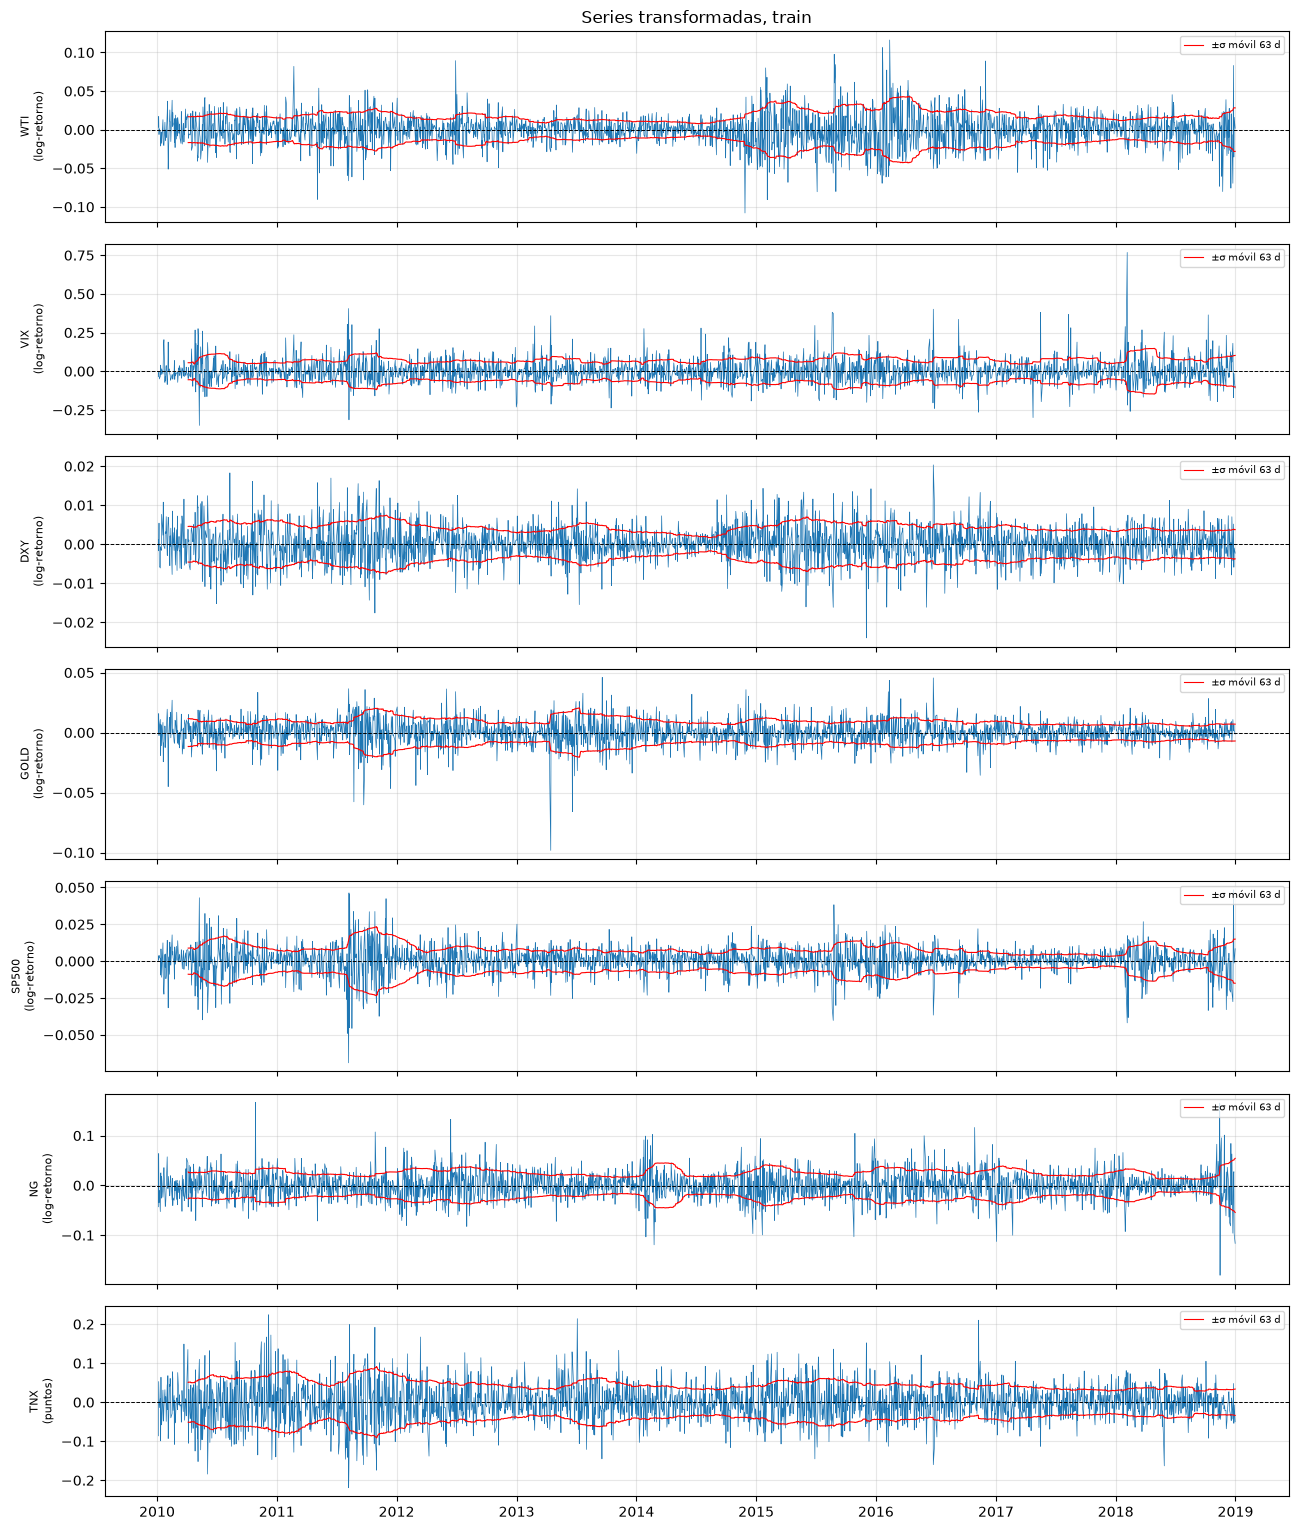

In [5]:
eda.graficar_series_transformadas(ret_train)

1. WTI — Precio del petróleo

El WTI presenta fluctuaciones alrededor de cero, con movimientos más intensos entre 2015 y 2016. Las bandas rojas se amplían en ese período, lo que indica un aumento de la volatilidad. Esto significa que el precio del petróleo experimentó cambios diarios más pronunciados. Para Ecuador, es relevante porque el petróleo influye en los ingresos por exportaciones y en los recursos fiscales.

2. VIX — Volatilidad esperada del mercado estadounidense

El VIX presenta numerosos picos positivos y negativos, incluido un pico positivo muy pronunciado en 2018. Esto muestra que sus variaciones pueden ser bruscas y que existen observaciones extremas. Una mayor variación del VIX significa que cambiaron las expectativas de volatilidad del mercado bursátil estadounidense; no necesariamente significa que el mercado haya caído.

3. DXY — Fortaleza del dólar

Las variaciones del DXY se concentran en una banda relativamente estrecha alrededor de cero, aunque existen algunos movimientos pronunciados. Esto indica que, en comparación con otras series de la gráfica, sus variaciones transformadas suelen tener menor magnitud. Para Ecuador, permite estudiar cambios en la fortaleza internacional del dólar y sus posibles efectos sobre la competitividad comercial.

4. GOLD — Precio del oro

El oro muestra variaciones alrededor de cero y algunos movimientos extremos, especialmente entre 2011 y 2013. Posteriormente, las fluctuaciones parecen moderarse en varios períodos. Esto sugiere que el oro alternó episodios de mayor volatilidad con otros de mayor estabilidad. Es útil para analizar el comportamiento de un activo considerado tradicionalmente como refugio financiero.

5. SP500 — Mercado bursátil estadounidense

El S&P 500 presenta fluctuaciones relativamente moderadas en varios tramos, pero también muestra movimientos pronunciados al inicio de la muestra y alrededor de 2018. Las bandas rojas cambian de amplitud, lo que indica que la volatilidad no fue constante. Esto permite identificar períodos de mayor incertidumbre en el mercado accionario estadounidense.

6. NG — Precio del gas natural

El gas natural presenta oscilaciones amplias y varios movimientos extremos. Las bandas rojas muestran cambios importantes de amplitud, especialmente alrededor de 2014 y en otros períodos. Esto indica que la volatilidad del gas natural varía considerablemente con el tiempo, posiblemente en respuesta a cambios en la oferta, la demanda y las condiciones del mercado energético.

7. TNX — Rendimiento del bono del Tesoro estadounidense a 10 años

El TNX presenta fluctuaciones alrededor de cero y algunos movimientos pronunciados. La amplitud de las bandas rojas cambia a lo largo del período, indicando variaciones en la volatilidad de los cambios diarios del rendimiento. Para Ecuador, es relevante porque las tasas de interés estadounidenses influyen en las condiciones internacionales de financiamiento en dólares, aunque el costo efectivo para el país también depende del riesgo soberano.

## 2. Series transformadas y outliers (|z| > 5, con σ de train)

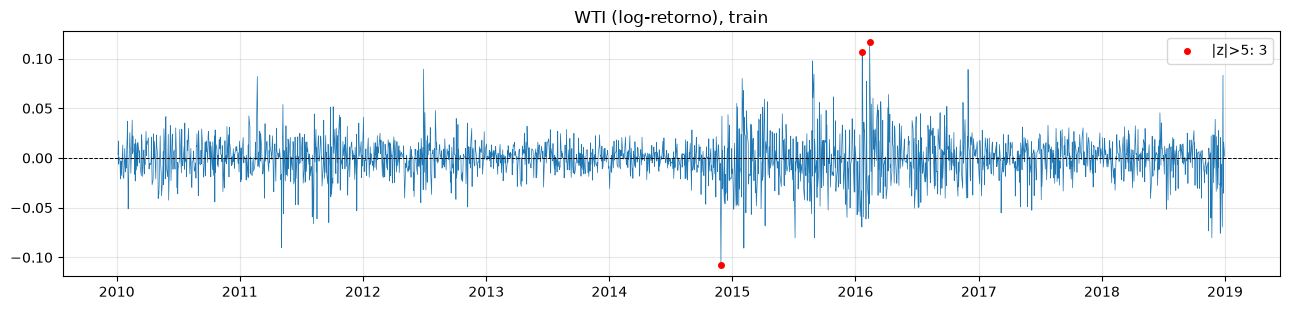

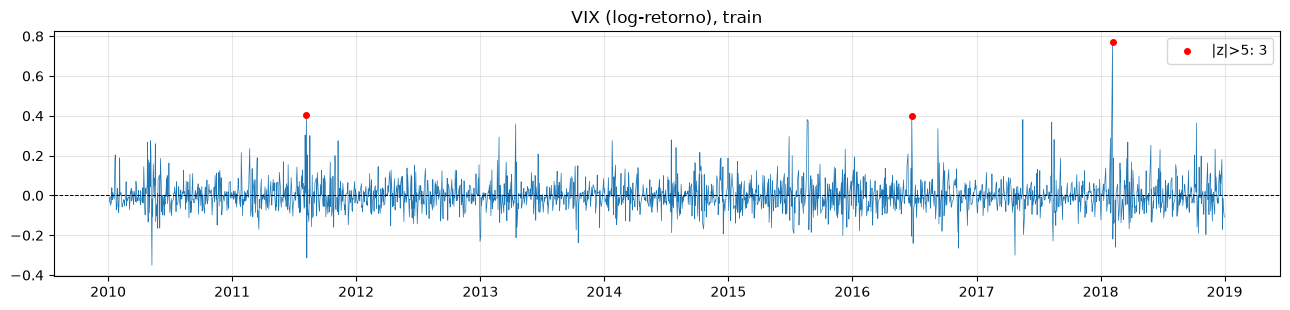

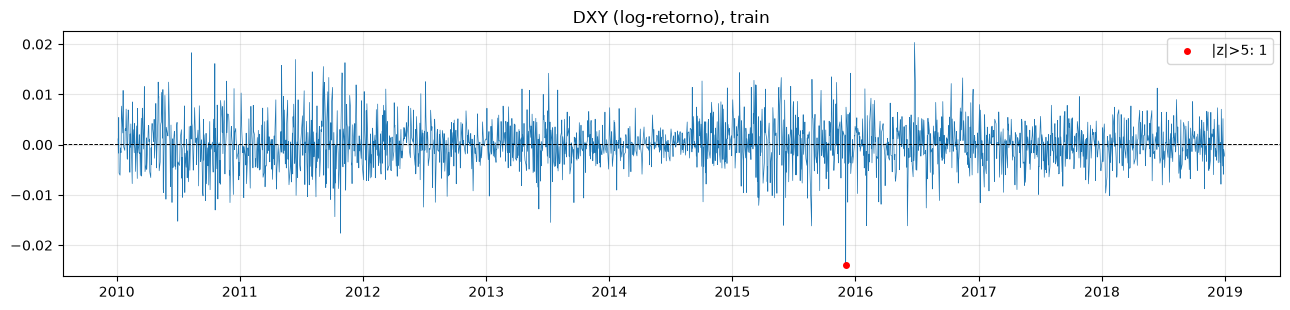

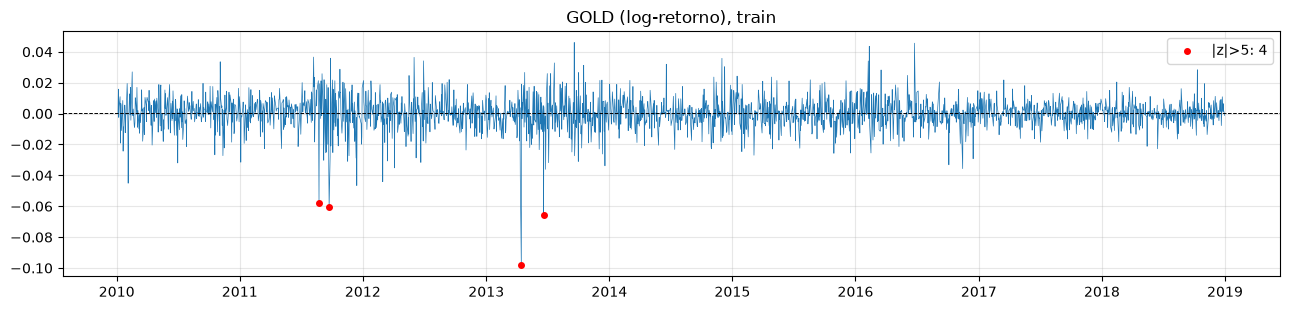

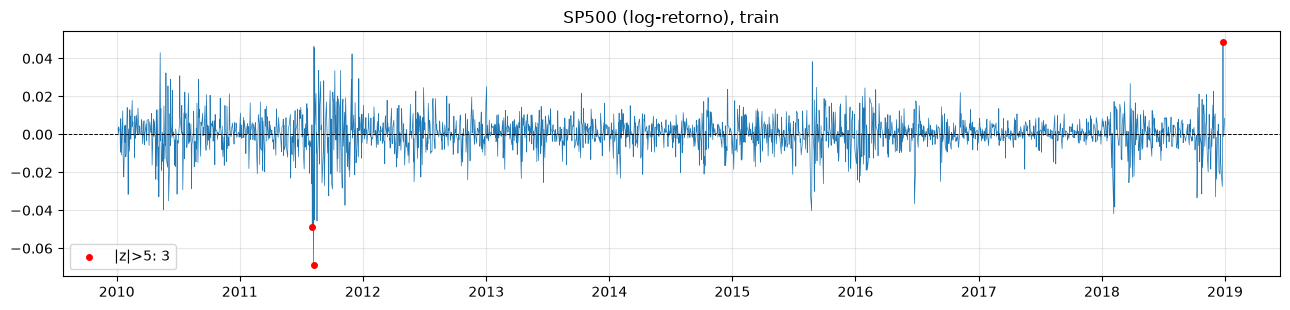

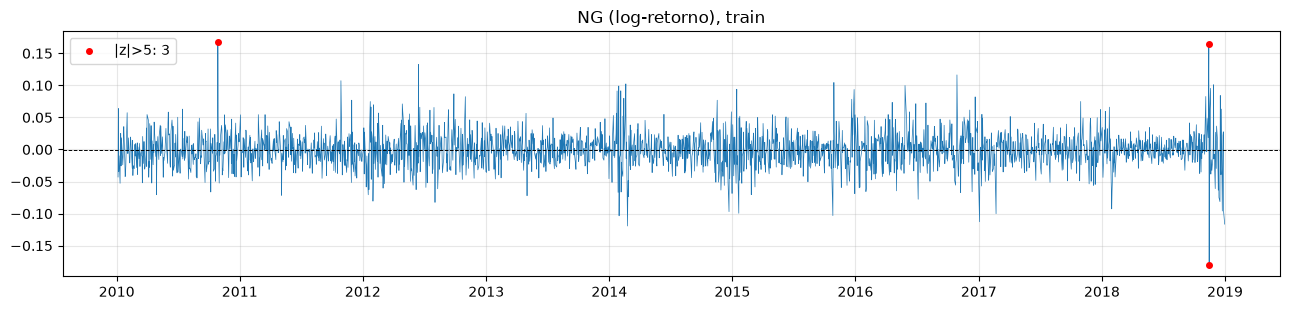

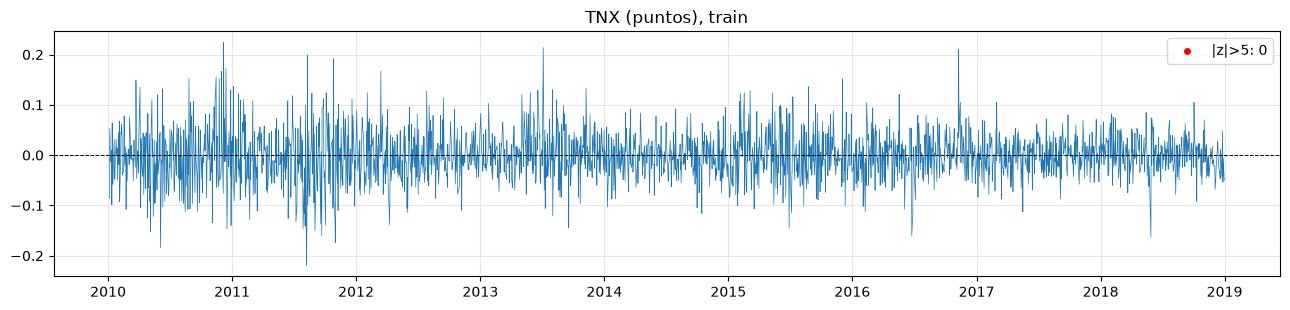

In [11]:
for c in ret_train.columns:
    eda.graficar_serie(ret_train[c], c)

In [12]:
# Fechas de los outliers: revisar si son eventos reales o cambios de contrato. No se eliminan.
filas = []
for c in ret_train.columns:
    for fecha, v in eda.outliers_z(ret_train[c]).items():
        filas.append({"serie": c, "fecha": fecha.date(), "valor": round(v, 4)})
pd.DataFrame(filas)

,serie,fecha,valor
0,WTI,2014-11-28,-0.1079
1,WTI,2016-01-21,0.1064
2,WTI,2016-02-12,0.1162
3,VIX,2011-08-08,0.4055
4,VIX,2016-06-24,0.4010
5,VIX,2018-02-05,0.7682
6,DXY,2015-12-03,-0.0240
7,GOLD,2011-08-24,-0.0577
8,GOLD,2011-09-23,-0.0603
9,GOLD,2013-04-15,-0.0982


## 3. Distribución, regímenes de volatilidad y apalancamiento

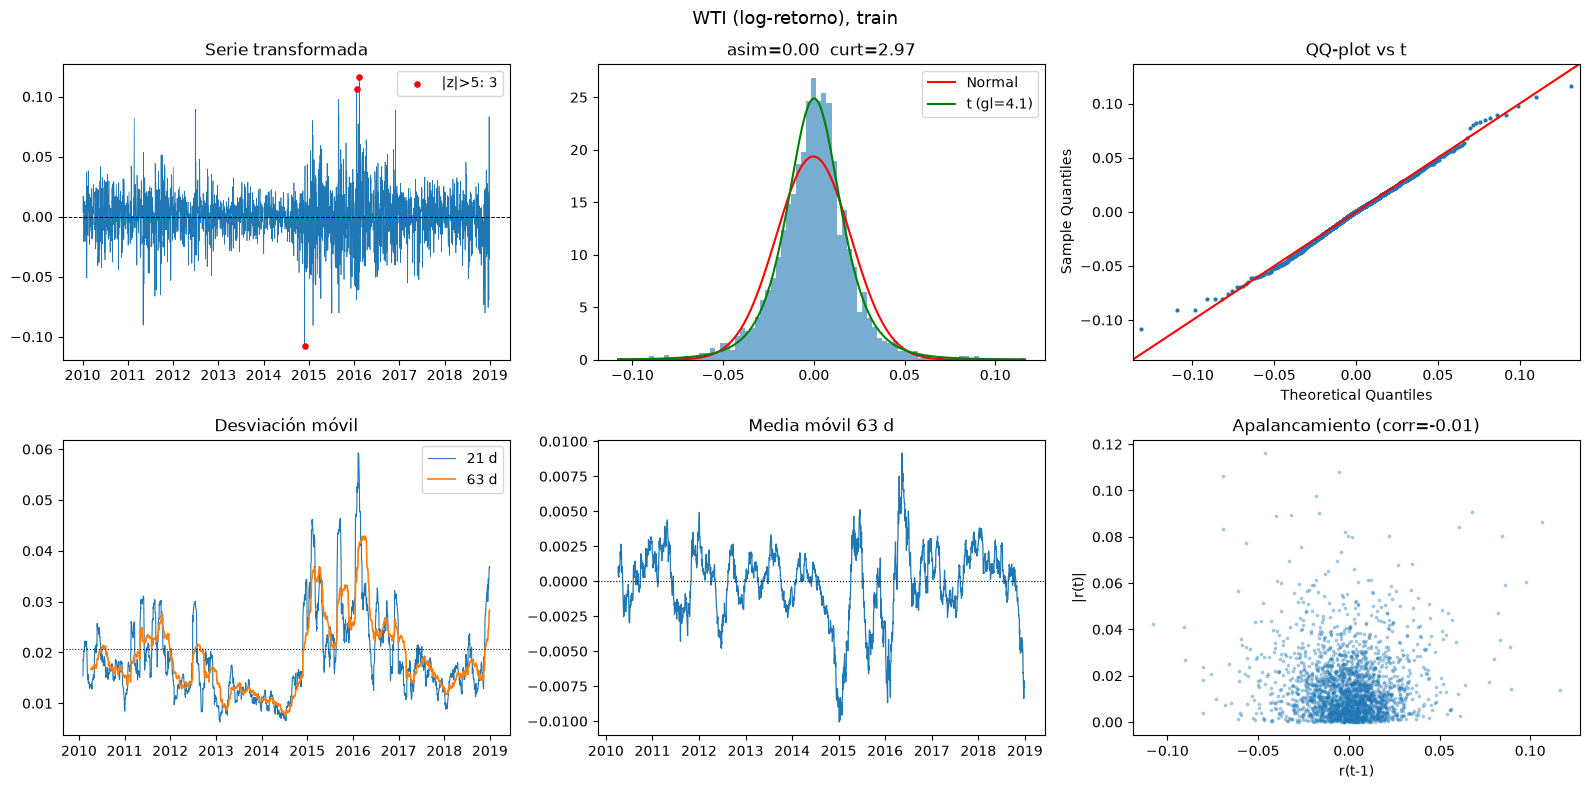

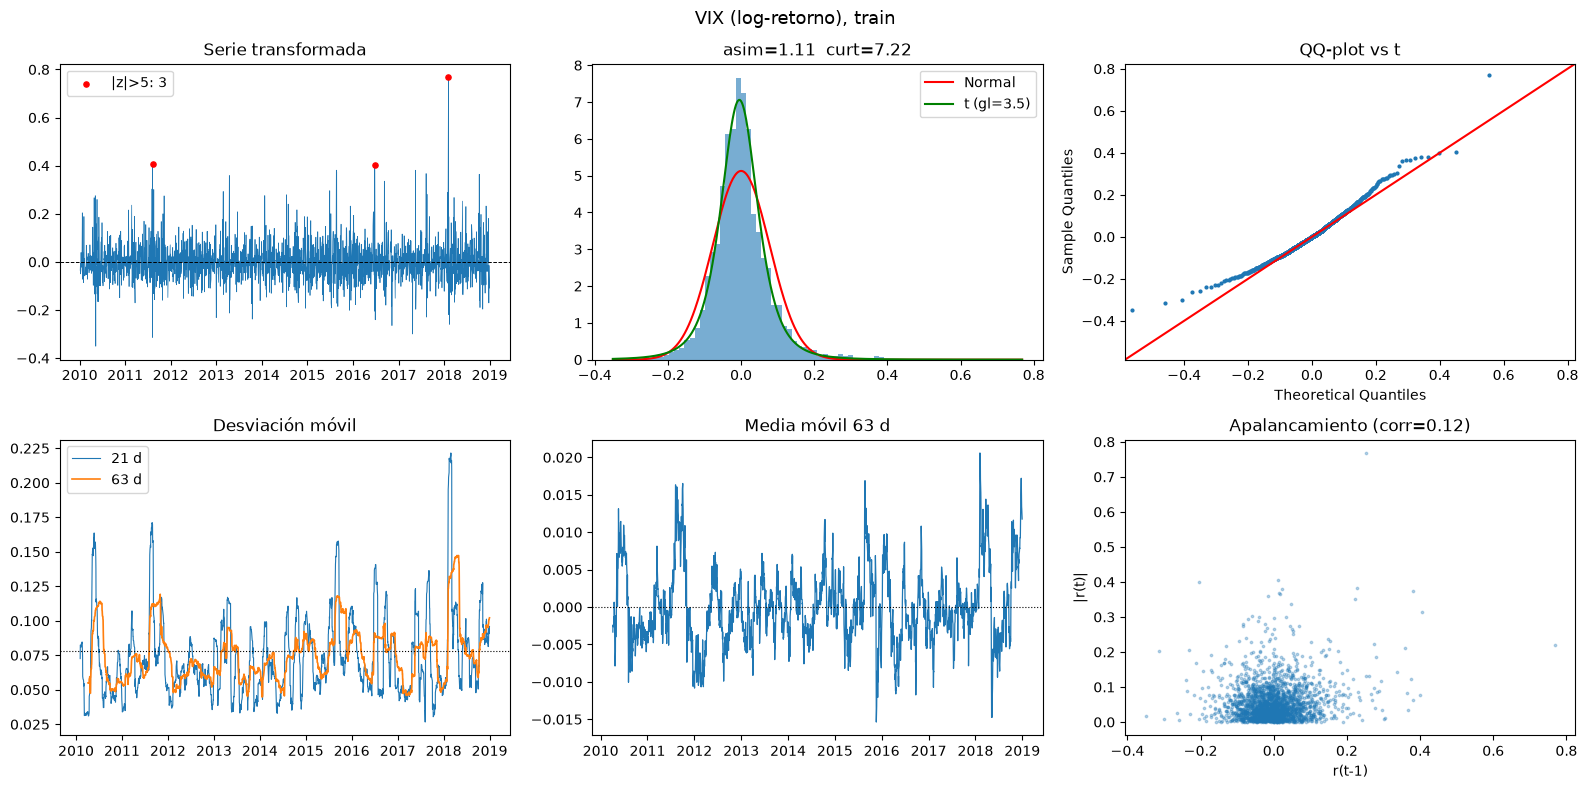

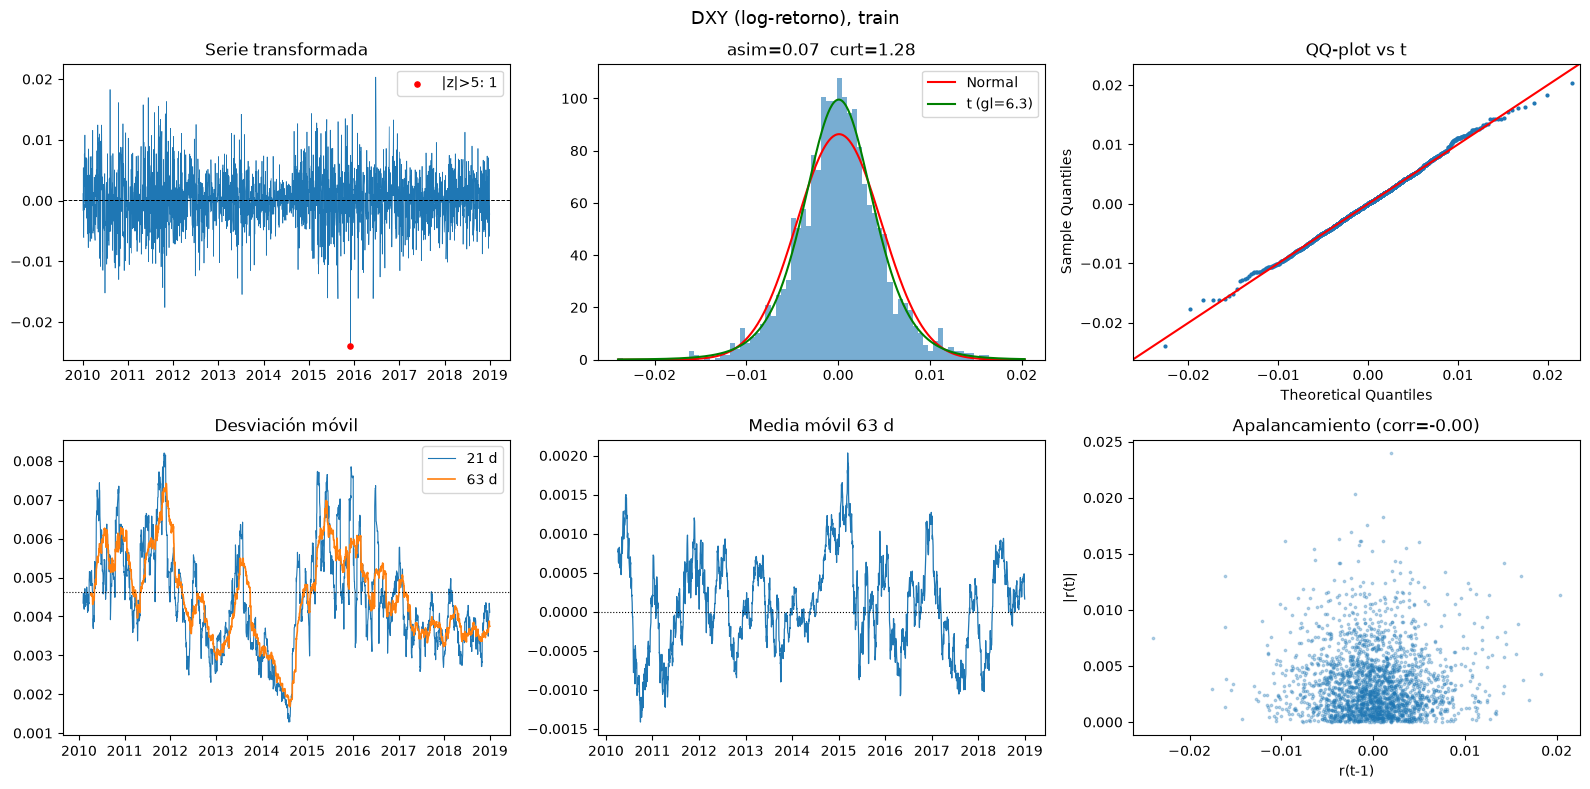

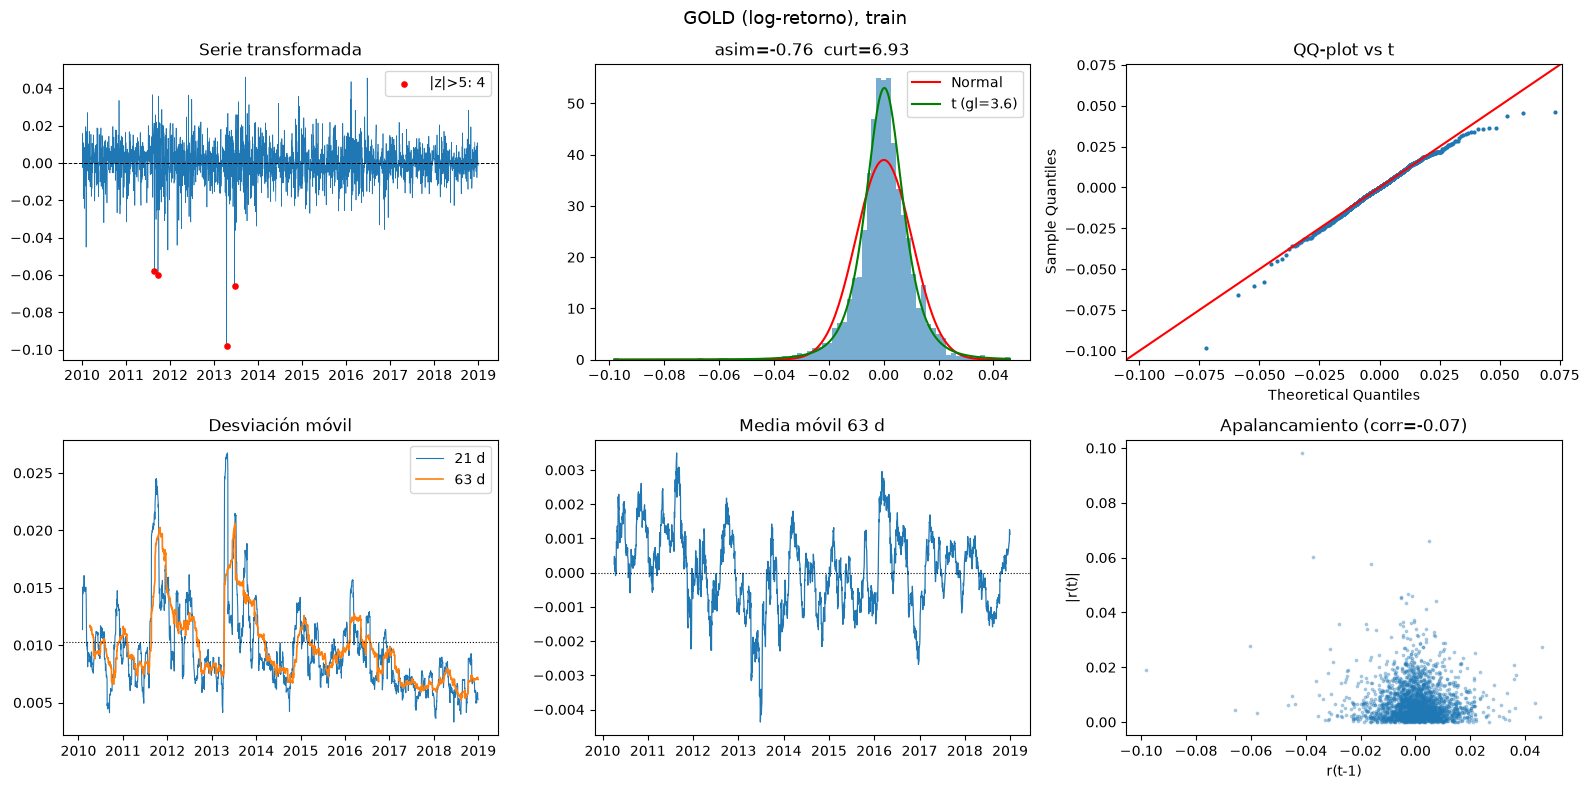

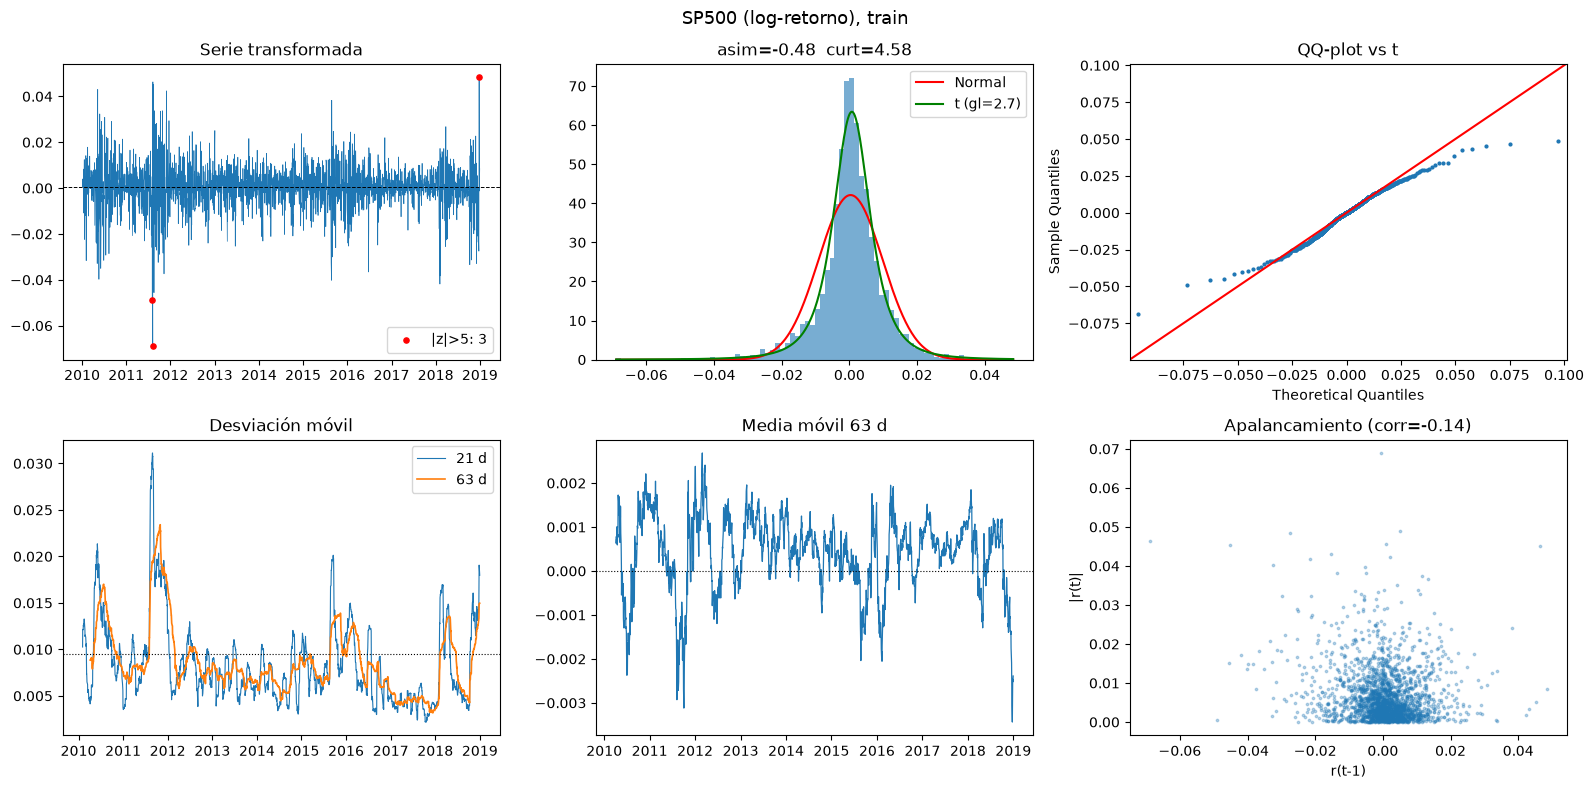

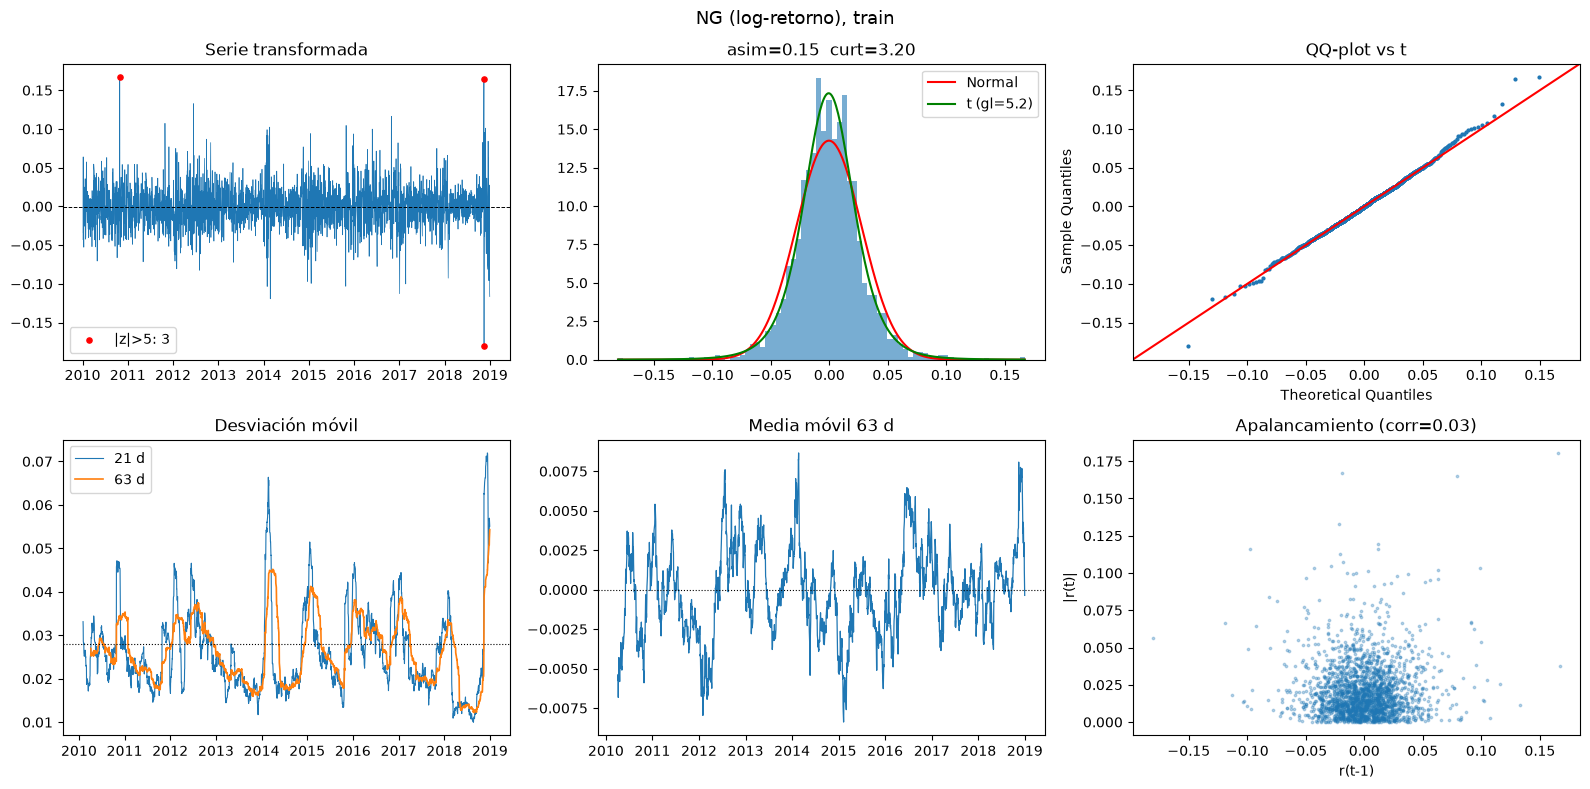

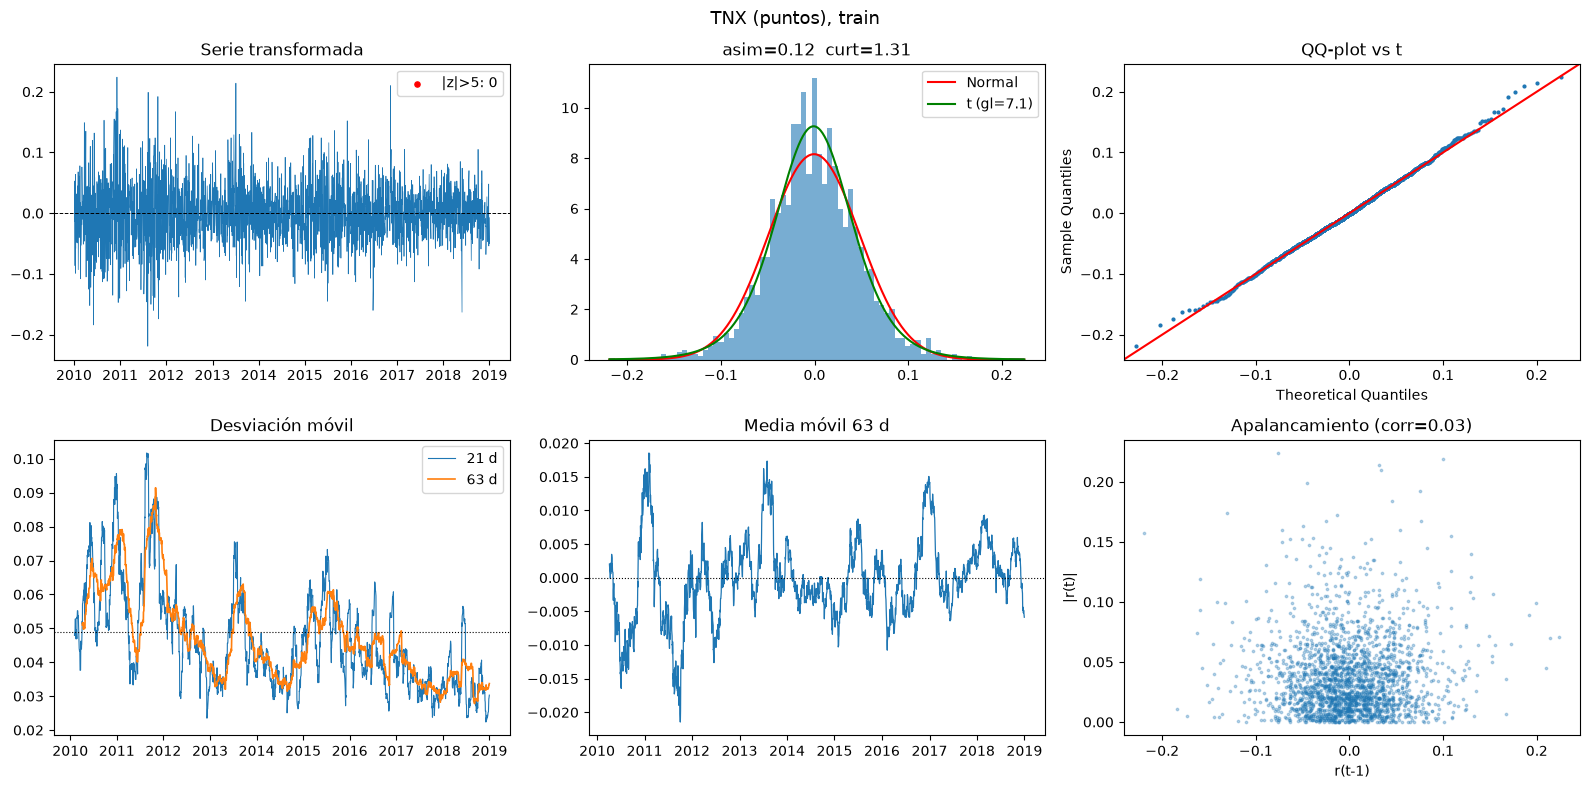

In [13]:
for c in ret_train.columns:
    eda.graficar_panel(ret_train[c], c)

## 4. Dependencia temporal: ACF de r, ACF de r² y PACF de r

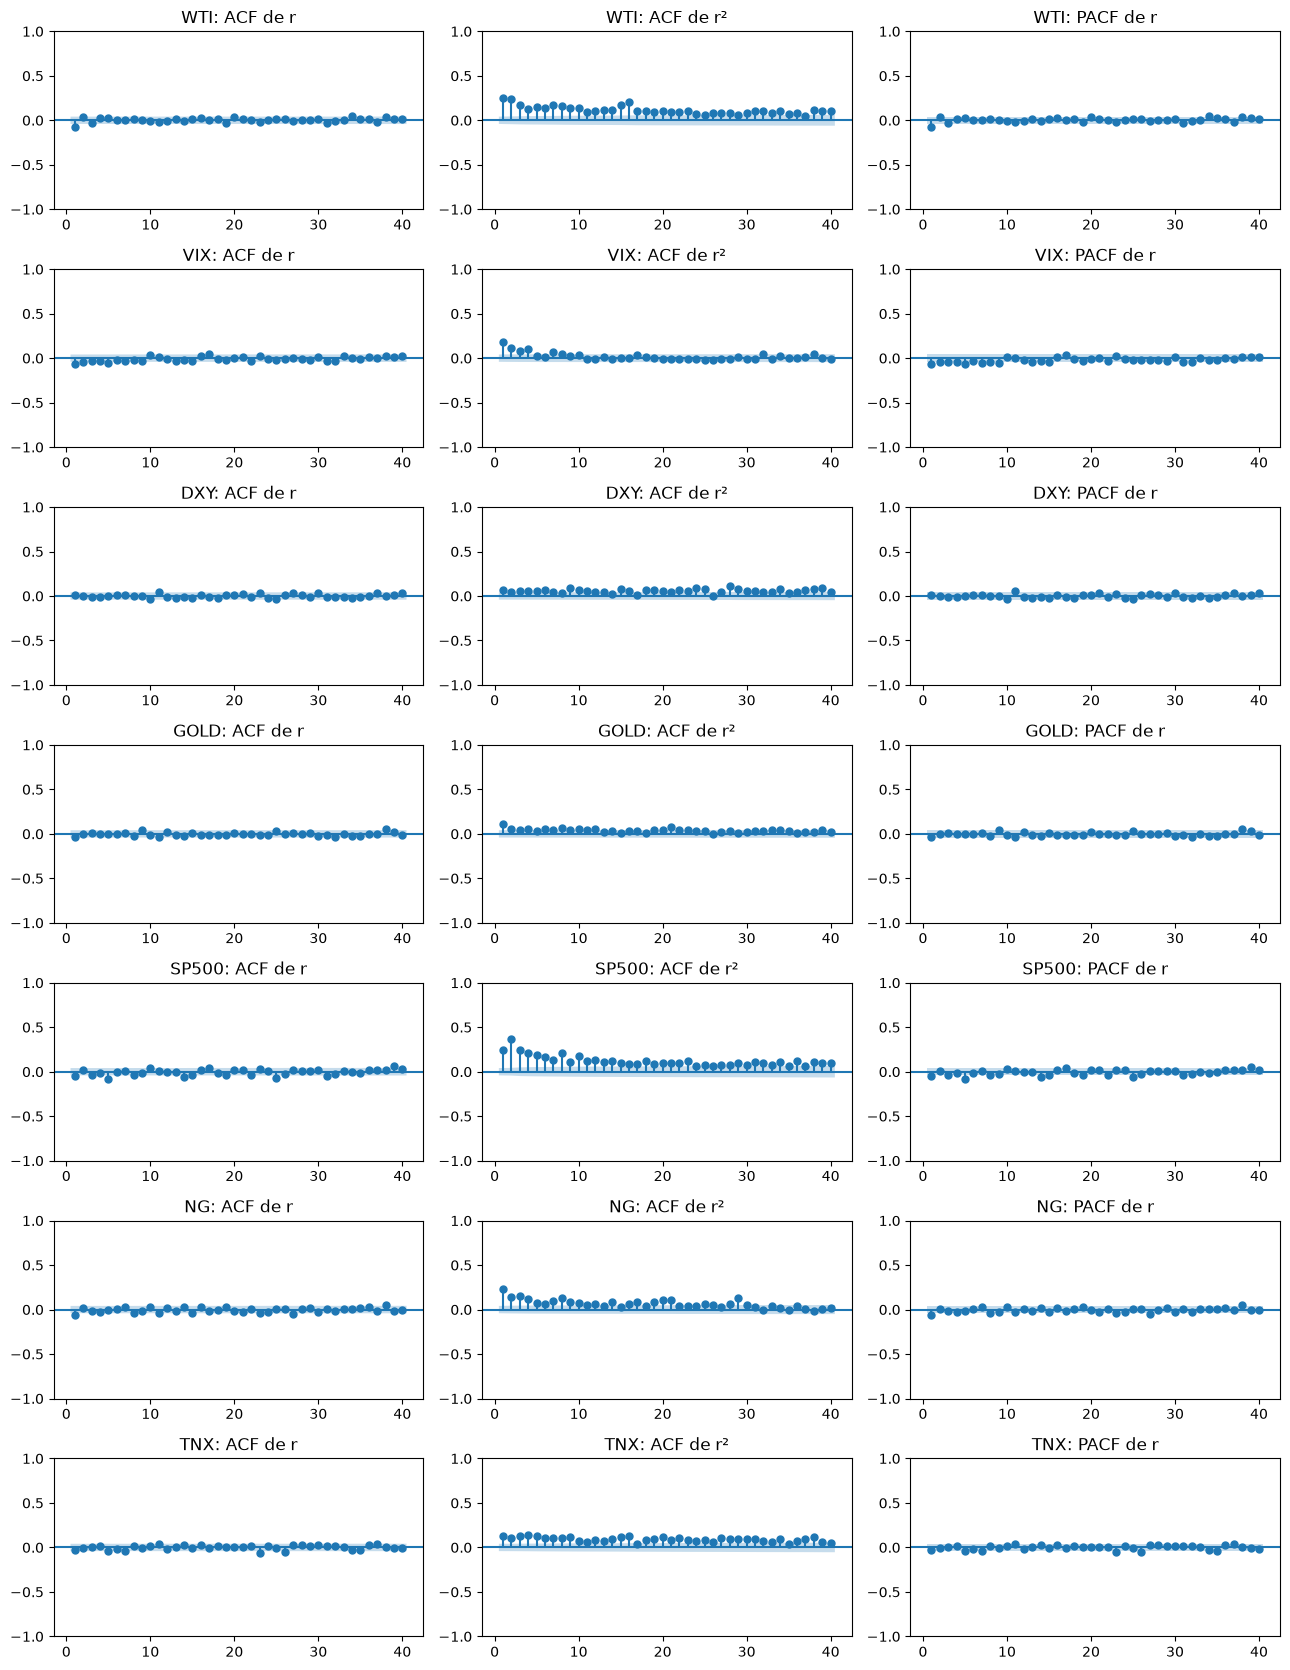

In [14]:
eda.graficar_acf(ret_train, lags=40)

1. WTI: La ACF de \(r\) se concentra alrededor de cero, con pocos rezagos que parecen sobresalir de las bandas de confianza. La ACF de \(r^2\) presenta autocorrelaciones positivas persistentes, lo que sugiere que períodos de alta volatilidad tienden a agruparse. La PACF de \(r\) también se concentra cerca de cero, sin un patrón autorregresivo claramente definido.

2. VIX: La ACF de \(r\) muestra autocorrelaciones pequeñas, generalmente cercanas a cero. La ACF de \(r^2\) presenta algunos valores positivos en los primeros rezagos, lo que sugiere cierta persistencia en la volatilidad. La PACF de \(r\) muestra valores pequeños y no evidencia un patrón autorregresivo marcado.

3. DXY: La ACF de \(r\) presenta valores muy próximos a cero, lo que sugiere poca dependencia lineal entre los rendimientos diarios. La ACF de \(r^2\) muestra autocorrelaciones positivas pequeñas en varios rezagos, aunque menos pronunciadas que en WTI o SP500. La PACF de \(r\) también se mantiene cerca de cero, sin un patrón claro.

4. GOLD: La ACF de \(r\) presenta autocorrelaciones pequeñas y concentradas alrededor de cero. La ACF de \(r^2\) muestra algunos valores positivos, pero en general de magnitud reducida, lo que sugiere una persistencia de volatilidad menos marcada visualmente. La PACF de \(r\) tampoco muestra un patrón autorregresivo evidente.

5. SP500: La ACF de \(r\) se encuentra mayormente concentrada alrededor de cero, lo que indica poca dependencia lineal en los rendimientos. En cambio, la ACF de \(r^2\) presenta autocorrelaciones positivas y persistentes, lo que sugiere agrupamiento de volatilidad. La PACF de \(r\) muestra valores pequeños, sin una estructura autorregresiva claramente definida.

6. NG: La ACF de \(r\) presenta valores cercanos a cero, con pocos rezagos que muestran una dependencia apreciable. La ACF de \(r^2\) evidencia autocorrelaciones positivas en numerosos rezagos, lo que sugiere persistencia en la volatilidad. La PACF de \(r\) permanece alrededor de cero, sin un patrón autorregresivo fuerte.

7. TNX: La ACF de \(r\) muestra autocorrelaciones generalmente pequeñas, con algunos valores aislados negativos. La ACF de \(r^2\) presenta autocorrelaciones positivas en varios rezagos, lo que sugiere cierta persistencia en la magnitud de las variaciones. La PACF de \(r\) se concentra alrededor de cero, sin un patrón autorregresivo evidente.

Conclusión general: En las siete variables, la ACF y la PACF de los rendimientos presentan, visualmente, poca dependencia lineal. Sin embargo, la ACF de los rendimientos al cuadrado muestra una persistencia más clara en WTI, SP500 y NG, lo que sugiere que conviene investigar la presencia de heterocedasticidad condicional mediante pruebas ARCH-LM.

### Pruebas formales de dependencia, normalidad y estacionariedad

Cuantifican lo que se ve en la ACF/PACF.

| Prueba | H0 | Si p < 0,05 |
|---|---|---|
| Ljung-Box sobre r | sin autocorrelación en r | hay autocorrelación en los rendimientos |
| Ljung-Box sobre r² | sin autocorrelación en r² | la magnitud de los movimientos es predecible |
| ARCH-LM | sin efecto ARCH | la varianza condicional depende del pasado |
| Jarque-Bera | normalidad | se aparta de la normal |
| ADF | raíz unitaria | estacionaria |
| KPSS | estacionariedad | evidencia contra la estacionariedad |

In [19]:
pruebas = eda.pruebas_dependencia(ret_train, lags=(5, 10, 20))
with pd.option_context("display.float_format", "{:.4g}".format, "display.max_rows", None):
    display(eda.resumen_pruebas(pruebas, rezago_ref=10))   # p-valores, rezago 10

prueba,Ljung-Box r,Ljung-Box r²,ARCH-LM,Jarque-Bera,ADF,KPSS
serie,,,,,,
WTI,0.02338,8.438e-137,4.853e-55,4.764e-181,0,0.1
VIX,5.423e-05,5.26e-29,1.076e-19,0,2.945e-28,0.1
DXY,0.9117,5.106e-14,1.078e-08,1.061e-34,0,0.1
GOLD,0.4407,2.486e-13,1.629e-08,0,0,0.1
SP500,0.0007839,6.322e-222,3.097e-88,0,1.429e-18,0.1
NG,0.05053,6.692e-72,1.472e-38,2.519e-211,0,0.1
TNX,0.2796,1.773e-57,2.178e-26,6.263e-37,0,0.1


1. Ljung–Box de \(r\): autocorrelación de los rendimientos
- WTI, VIX, SP500 y NG: sus valores p son inferiores a 0.05, por lo que se rechaza la hipótesis de ausencia de autocorrelación.
- DXY, GOLD y TNX: sus valores p son superiores a 0.05, por lo que no se rechaza la hipótesis nula. No se encuentra evidencia suficiente de autocorrelación conjunta al rezago evaluado.
Esto sugiere que algunas series presentan dependencia temporal en sus rendimientos, mientras que otras muestran un comportamiento más cercano a rendimientos sin autocorrelación lineal.

2. Ljung–Box de \(r^2\): dependencia en la magnitud de los rendimientos
Las siete series presentan valores p muy inferiores a 0.05. Por tanto, se rechaza la hipótesis nula para todas ellas.
Esto indica que existe dependencia temporal en los rendimientos al cuadrado, lo que sugiere que la magnitud de las fluctuaciones no es completamente aleatoria y puede presentar persistencia.

3. ARCH-LM: heterocedasticidad condicional
En las siete variables se rechaza la hipótesis nula de ausencia de efectos ARCH, dado que los valores p son inferiores a 0.05.
Esto proporciona evidencia de que la varianza condicional cambia con el tiempo. Por ello, conviene evaluar modelos de volatilidad como ARCH o GARCH, especialmente para pronosticar la volatilidad.

4. Jarque–Bera: normalidad
Los valores p son inferiores a 0.05 en las siete series. Por tanto, se rechaza la hipótesis de normalidad de los rendimientos.
Esto indica que las distribuciones presentan desviaciones respecto de la normalidad, que pueden estar relacionadas con asimetría, colas pesadas o ambas.

5. ADF: raíz unitaria
Los valores p reportados son prácticamente cero en todas las series. Se rechaza la hipótesis nula de raíz unitaria, lo que proporciona evidencia a favor de la estacionariedad según la especificación utilizada en la prueba.

6. KPSS: estacionariedad
La tabla muestra valores p de 0.1 para todas las variables. Si 0.1 es el valor p reportado por la función y no un valor fijo asignado, no se rechaza la hipótesis nula de estacionariedad al 5 %.

In [20]:
# Detalle completo (estadístico, p-valor, decisión y lectura) para una serie
pruebas[pruebas["serie"] == "WTI"]

,serie,prueba,rezagos,estadistico,p_valor,H0,rechaza_H0,lectura
0,WTI,Ljung-Box r,5,20.0992,1.197300e-03,sin autocorrelación en r,True,hay autocorrelación en r
1,WTI,Ljung-Box r²,5,418.8766,2.530244e-88,sin autocorrelación en r²,True,la magnitud de los movimientos es predecible (...
2,WTI,ARCH-LM,5,243.8571,1.142738e-50,sin efecto ARCH,True,efecto ARCH: la varianza depende del pasado
3,WTI,Ljung-Box r,10,20.6882,2.337592e-02,sin autocorrelación en r,True,hay autocorrelación en r
4,WTI,Ljung-Box r²,10,666.7853,8.438391e-137,sin autocorrelación en r²,True,la magnitud de los movimientos es predecible (...
5,WTI,ARCH-LM,10,283.4574,4.852645e-55,sin efecto ARCH,True,efecto ARCH: la varianza depende del pasado
6,WTI,Ljung-Box r,20,30.3762,6.398319e-02,sin autocorrelación en r,False,sin autocorrelación en r
7,WTI,Ljung-Box r²,20,1029.4524,2.038561e-205,sin autocorrelación en r²,True,la magnitud de los movimientos es predecible (...
8,WTI,ARCH-LM,20,332.7934,1.546516e-58,sin efecto ARCH,True,efecto ARCH: la varianza depende del pasado
9,WTI,Jarque-Bera,-,830.4136,4.764001e-181,distribución normal,True,se aparta de la normal (asimetría y/o colas)


1. Autocorrelación de los rendimientos (Ljung–Box): Para 5 y 10 rezagos se rechaza la hipótesis nula, por lo que existe evidencia de autocorrelación en los rendimientos. Para 20 rezagos no se rechaza, por lo que no se encuentra evidencia suficiente de autocorrelación conjunta a ese nivel.

2. Autocorrelación de los rendimientos al cuadrado (Ljung–Box): Se rechaza la hipótesis nula para 5, 10 y 20 rezagos. Esto indica que existe dependencia en la magnitud de los movimientos del petróleo y sugiere persistencia en la volatilidad.

3. Efectos ARCH (ARCH-LM): Se rechaza la hipótesis nula en los tres órdenes evaluados. Existe evidencia de heterocedasticidad condicional, por lo que sería conveniente evaluar modelos ARCH/GARCH para representar los cambios de volatilidad.

4. Normalidad (Jarque–Bera): Se rechaza la hipótesis de normalidad. Los rendimientos del WTI presentan una distribución que se aparta de la normal, posiblemente debido a asimetría, colas pesadas o ambas.

5. Estacionariedad (ADF y KPSS): La prueba ADF rechaza la hipótesis de raíz unitaria y la KPSS no rechaza la hipótesis de estacionariedad. Ambas pruebas respaldan la conclusión de que la serie transformada es estacionaria.

Conclusión general: Los rendimientos transformados del WTI parecen estacionarios, pero presentan evidencia de dependencia temporal en algunos rezagos, volatilidad cambiante y una distribución no normal.

## 5. Estacionalidad del gas natural

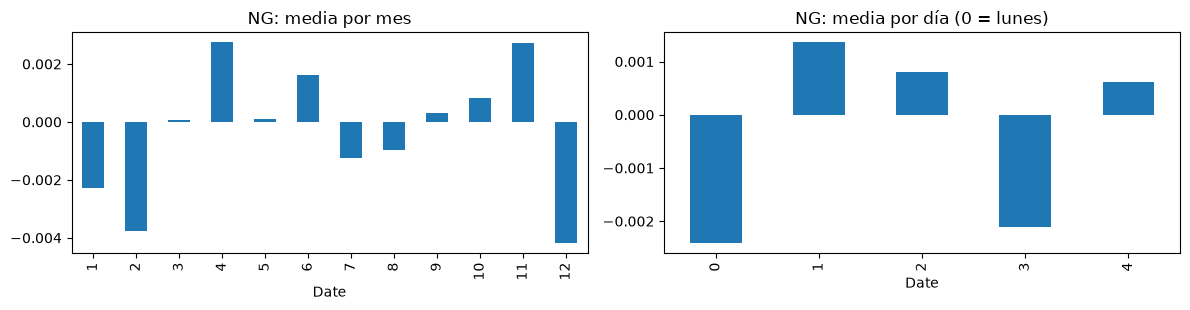

In [21]:
eda.graficar_estacionalidad(ret_train["NG"], "NG")

## 6. Evidencia para elegir K y H (ventanas) y piso de referencia

* **Piso de referencia por pliegue:** cualquier modelo debe compararse contra el pronóstico "cero" y la media de train.
* **Escalamiento con el horizonte:** razón de varianzas (VR ≈ 1: retornos casi independientes) y curtosis de los retornos acumulados.
* Con H grande hay pocas observaciones no solapadas: las estimaciones son orientativas.

In [22]:
eda.piso_referencia(ret_train["WTI"])

,pliegue,val_ini,val_fin,std_val,RMSE_cero,RMSE_media_train
0,1,2011-10-25,2013-08-12,0.01518,0.01517,0.01516
1,2,2013-08-14,2015-05-29,0.01973,0.01975,0.01977
2,3,2015-06-02,2017-03-17,0.02788,0.02785,0.02785
3,4,2017-03-21,2018-12-31,0.01819,0.01817,0.01817


Cada ventana representa un intervalo temporal en el que se examina el comportamiento de los rendimientos del WTI.

Observa que la desviación estándar pasa de 0.01518 en el primer período a 0.02788 en el tercero. Esto muestra que la variabilidad del WTI cambia entre períodos y que el modelo debe evaluarse en distintas condiciones de mercado.

In [23]:
eda.escalamiento_horizonte(ret_train["WTI"])

,H,n,std,VR,curtosis_exc
0,1,2259,0.0206,1.0000,2.9703
1,5,451,0.0452,0.9629,2.0999
2,10,225,0.0654,1.0069,2.0120
3,21,107,0.0908,0.9246,0.5192
4,42,53,0.1217,0.8302,3.1159
5,63,35,0.1720,1.1055,2.7863


In [24]:
ret_val = cargar("retornos", "val")
eda.comparar_train_val(ret_train, ret_val)

,serie,std_train,std_val,razon_std,KS_stat,KS_p
0,WTI,0.0206,0.0213,1.0325,0.0595,0.3823
1,VIX,0.0778,0.0749,0.9628,0.0572,0.4307
2,DXY,0.0046,0.0028,0.6157,0.1085,0.0088
3,GOLD,0.0102,0.0073,0.7086,0.0925,0.0387
4,SP500,0.0095,0.0079,0.8305,0.0602,0.3676
5,NG,0.0280,0.0269,0.9600,0.0372,0.9002
6,TNX,0.0489,0.0441,0.9015,0.0551,0.4786


## 8. Conclusiones

Estacionariedad confirmada. ADF rechaza la raíz unitaria (p ≈ 0) y KPSS no rechaza la estacionariedad en ninguna serie (estadístico entre 0,04 y 0,22, bajo el crítico del 5 %, que es 0,463). TNX es la que más se acerca (0,22). La transformación elegida funciona.

Colas pesadas en todas. Jarque-Bera rechaza la normalidad en todas (p ≈ 0). El t_gl incondicional es bajo, sobre todo en SP500 (2,66), VIX, GOLD y WTI (3,5 a 4,1). Este valor mezcla colas reales con agrupamiento de volatilidad, así que el t_gl del GARCH-t, que es condicional, saldrá más alto. Justifica el GARCH con t de Student, no la normal.

Volatilidad condicional justificada. Ljung-Box de r² y ARCH-LM rechazan en las siete (p ≤ 1e-8). Esto respalda tanto el GARCH-t como las arquitecturas con memoria (LSTM/GRU) y la salida probabilística.

Autocorrelación pequeña pero significativa en algunas. WTI (lag 1 = -0,07), VIX (-0,06, con barras negativas hasta el lag ~9) y SP500 (-0,04) rechazan Ljung-Box. Con 2.259 observaciones, el p-valor detecta efectos económicamente mínimos (≈ 0,5 % de varianza explicada). Una constante o AR(1) en el GARCH es suficiente.

Apalancamiento: corrijo lo que te dije antes. Esperaba efecto apalancamiento en WTI y SP500. Los datos lo confirman solo en el SP500 (-0,14), y en menor medida en GOLD (-0,07). En el WTI es prácticamente nulo (-0,01), así que un GARCH simétrico basta para él. Contrasta después con el parámetro γ de un GJR-GARCH. El +0,12 del VIX tiene lectura distinta: el VIX es en sí una medida de volatilidad, así que sube más después de subidas.

Riesgo extremo de referencia en train. WTI: VaR 1 % ≈ 5,7 % y ES 1 % ≈ 7,0 % diarios. Es la línea base contra la cual verás, en el Bloque 4, cuánto se queda corto un modelo entrenado en periodo normal. Solo como contexto de tu hipótesis: el log-retorno acumulado de -0,60 entre el 17 y el 21/04/2020 es muchas veces mayor que ese ES. No lo uses para decidir nada de diseño.